# Entry / exit multiples from Damodaran

MonteCarloRun.py was using a guessed 10x / 12x / 15.5x for entry and exit EV/EBITDA (Dewey has no valuation data).
This pulls Damodaran's US industry EV/EBITDA and uses the spread across industries instead.

Get `vebitda.xls` from https://pages.stern.nyu.edu/~adamodar/pc/datasets/vebitda.xls and put it in `data/`.
Older years (`vebitda12.xls` etc., from the archive page) can go in `data/` too and get pooled in.

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OLD = (10.0, 12.0, 15.5)   # what the MC used before
DISCOUNT = 0.0             # haircut for private mid-market vs public (0.15 = 15% cheaper). no source yet so 0

# EV/EBITDA doesn't mean much for these (debt is part of the business), so drop them
EXCLUDE = r"Bank|Brokerage|Financial Svcs|Insurance|Reinsurance|Investments|R\.E\.I\.T|REIT|Real Estate"

# where middle-market buyouts mostly happen; only used as a sanity check, not in the model
PE_SECTORS = ["Business & Consumer Services", "Healthcare Support Services", "Healthcare Products",
              "Heathcare Information and Technology", "Software (System & Application)", "Computer Services",
              "Information Services", "Machinery", "Electrical Equipment", "Building Materials",
              "Construction Supplies", "Engineering/Construction", "Environmental & Waste Services",
              "Chemical (Specialty)", "Packaging & Container", "Food Processing", "Household Products",
              "Retail (Distributors)", "Trucking", "Transportation", "Restaurant/Dining", "Education",
              "Advertising", "Recreation", "Aerospace/Defense"]

## Load

In [2]:
def load(path):
    # damodaran's sheet has a block of notes on top, so find the header row instead of hardcoding it
    df = pd.read_excel(path, sheet_name="Industry Averages", header=None)
    hdr = df.index[df[0].eq("Industry Name")][0]
    year = pd.to_datetime(df.iloc[0, 1]).year          # 'Date updated' cell, top of sheet

    # cols: name, # firms, EV/EBITDAR&D, EV/EBITDA (first EV/EBITDA = positive-EBITDA firms only)
    t = df.iloc[hdr + 1:, [0, 1, 3]].dropna()
    t.columns = ["industry", "n_firms", "ev_ebitda"]
    t["industry"] = t.industry.str.replace(r"\s+", " ", regex=True).str.strip()   # names have line breaks in them
    t["ev_ebitda"] = pd.to_numeric(t.ev_ebitda, errors="coerce")
    t["year"] = year
    return t

df = pd.concat(load(p) for p in sorted(glob.glob("data/vebitda*.xls")))
df = df[~df.industry.str.contains(EXCLUDE + "|Total Market")]   # also drop the market-wide summary rows
df = df[df.ev_ebitda > 0]
df["ev_ebitda"] *= 1 - DISCOUNT

print(f"years: {sorted(df.year.unique())}   industries: {df.industry.nunique()}")

years: [np.int64(2026)]   industries: 80


## How does the old range compare?

0.10     8.1
0.25     9.6
0.50    12.5
0.75    16.8
0.90    24.1

industries inside old 10.0-15.5x range: 42%


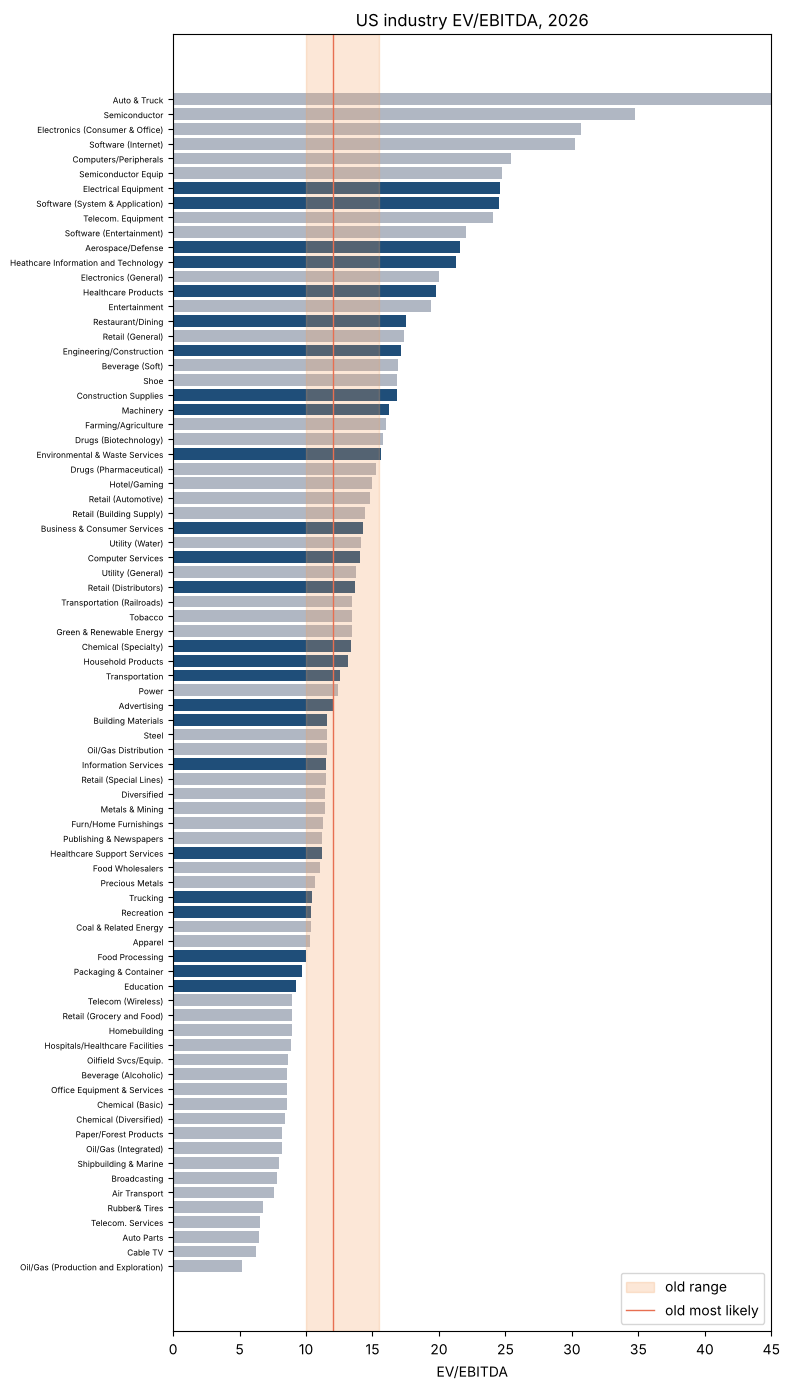

In [3]:
latest = df[df.year == df.year.max()].sort_values("ev_ebitda")

# each industry counts once (not weighted by # firms) since we want the spread of 'types of business'
print(latest.ev_ebitda.quantile([.1, .25, .5, .75, .9]).round(1).to_string())
inside = latest.ev_ebitda.between(OLD[0], OLD[2]).mean()
print(f"\nindustries inside old {OLD[0]}-{OLD[2]}x range: {inside:.0%}")

# dark bars = PE-heavy sectors, orange band = old assumption
fig, ax = plt.subplots(figsize=(8, 14))
ax.barh(latest.industry, latest.ev_ebitda,
        color=np.where(latest.industry.isin(PE_SECTORS), "#1f4e79", "#b0b7c3"))
ax.axvspan(OLD[0], OLD[2], color="#f4a261", alpha=.25, label="old range")
ax.axvline(OLD[1], color="#e76f51", lw=1, label="old most likely")
ax.set(xlabel="EV/EBITDA", xlim=(0, 45), title=f"US industry EV/EBITDA, {latest.year.iloc[0]}")
ax.tick_params(axis="y", labelsize=6)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## Triangular params → `data/multiple_params.csv`

low / most likely / high = 10th / 50th / 90th percentile across industries (all years pooled).
One range for everything since the model is a generic deal, not a specific company. Entry and exit both use it.

In [4]:
lo, mode, hi = df.ev_ebitda.quantile([.1, .5, .9]).round(2)
pd.DataFrame([{"low": lo, "mode": mode, "high": hi}]).to_csv("data/multiple_params.csv", index=False)

pe = df[df.industry.isin(PE_SECTORS)].ev_ebitda.quantile([.1, .5, .9])
print(f"old:              {OLD[0]:.1f} / {OLD[1]:.1f} / {OLD[2]:.1f}")
print(f"new (all):        {lo:.1f} / {mode:.1f} / {hi:.1f}   <- written to csv")
print(f"PE sectors only:  {pe.iloc[0]:.1f} / {pe.iloc[1]:.1f} / {pe.iloc[2]:.1f}   (just for reference)")

old:              10.0 / 12.0 / 15.5
new (all):        8.1 / 12.5 / 24.1   <- written to csv
PE sectors only:  10.2 / 13.7 / 21.5   (just for reference)


## Still to do
- add archive years so the range covers more than one market snapshot (Jan 2026 is a pricey market)
- with archives, measure how much multiples move over a 5-7 yr hold → sets the entry/exit correlation in the MC (currently off)
- set `DISCOUNT` once we have a private deal multiple benchmark